### 1. Import Data

In [7]:
import sys
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [8]:
ALPHA = 0.05

def judul(teks):
    print("\n" + "=" * 70 + f"\n{teks}\n" + "=" * 70)

### 2. Memuat dan Memahami Data

skipinitialspace: alamat berisi koma, jadi kolom bergeser. Kolom
"Purchase Address" = jalan, "City" = kota, "Postal Code" = "STATE KODEPOS".

In [9]:
df = pd.read_csv("ecommerce-sales-clean.csv", skipinitialspace=True)

judul("1. STRUKTUR DATA")
print(df.dtypes)
print("\nJumlah baris:", len(df))
print("Missing value per kolom:\n", df.isna().sum())
print("Baris duplikat:", df.duplicated().sum())


1. STRUKTUR DATA
Order ID              int64
Product              object
Quantity Ordered      int64
Price Each          float64
Order Date           object
Purchase Address     object
City                 object
Postal Code          object
dtype: object

Jumlah baris: 3852
Missing value per kolom:
 Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
City                0
Postal Code         0
dtype: int64
Baris duplikat: 3


Asumsi: baris yang persis sama (Order ID, produk, waktu, alamat) dianggap duplikat.
Bisa juga produk yang sama dibeli dua kali dalam satu order; dampaknya kecil, dicetak di bawah.

In [10]:

dup = df[df.duplicated()]
print(f"Nilai baris duplikat yang dibuang: {(dup['Quantity Ordered']*dup['Price Each']).sum():,.2f}")
df = df.drop_duplicates().copy()
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["State"] = df["Postal Code"].str.split().str[0]
df["CityState"] = df["City"] + ", " + df["State"]  # bedakan Portland OR vs ME
df["Revenue"] = df["Quantity Ordered"] * df["Price Each"]
df["Month"] = df["Order Date"].dt.month
df["Hour"] = df["Order Date"].dt.hour
df["DOW"] = df["Order Date"].dt.dayofweek
df["Tier"] = np.where(df["Price Each"] >= 300, "Premium (>=$300)", "Aksesori/Menengah (<$300)")

Nilai baris duplikat yang dibuang: 411.94


In [11]:
print("\nPeriode (tanggal-waktu):", df["Order Date"].min(), "->", df["Order Date"].max())
print("Jam order (hour) min/maks:", df["Order Date"].dt.hour.min(), "/", df["Order Date"].dt.hour.max())
print("Order per bulan (cek sebaran):\n", df.groupby("Month")["Order ID"].nunique().to_string())


Periode (tanggal-waktu): 2019-01-01 06:13:00 -> 2019-12-31 22:58:00
Jam order (hour) min/maks: 0 / 23
Order per bulan (cek sebaran):
 Month
1     647
2      72
3     993
4     341
5      57
6     330
7     195
8     304
9     189
10    270
11     63
12    246


Tingkat order: satu Order ID bisa punya beberapa baris produk

In [12]:
orders = df.groupby("Order ID").agg(
    rev=("Revenue", "sum"),
    baris=("Product", "count"),            # jumlah baris item
    produk_unik=("Product", "nunique"),    # jumlah jenis produk berbeda
    unit=("Quantity Ordered", "sum"),      # jumlah unit barang
    city=("CityState", "first"),
    date=("Order Date", "first"),
).reset_index()
orders["weekend"] = orders["date"].dt.dayofweek >= 5
orders["hour"] = orders["date"].dt.hour

### 3. Statistik Deskriptif

In [13]:
judul("2. STATISTIK DESKRIPTIF (nilai per baris item)")
r = df["Revenue"]
print(f"Mean     : {r.mean():,.2f}")
print(f"Median   : {r.median():,.2f}")
print(f"Modus    : {r.mode()[0]:,.2f}")
print(f"Std      : {r.std():,.2f}")
print(f"Varians  : {r.var():,.2f}")
print(f"Min/Max  : {r.min():,.2f} / {r.max():,.2f}")
print(f"Q1/Q3/IQR: {r.quantile(.25):,.2f} / {r.quantile(.75):,.2f} / {r.quantile(.75)-r.quantile(.25):,.2f}")
print(f"CV       : {r.std()/r.mean():.2f}")
print(f"Skewness : {stats.skew(r):.2f}   Kurtosis: {stats.kurtosis(r):.2f}")


2. STATISTIK DESKRIPTIF (nilai per baris item)
Mean     : 177.62
Median   : 14.95
Modus    : 14.95
Std      : 323.56
Varians  : 104,688.46
Min/Max  : 2.99 / 1,700.00
Q1/Q3/IQR: 11.95 / 150.00 / 138.05
CV       : 1.82
Skewness : 2.98   Kurtosis: 9.91


In [14]:
n = len(orders)
se = orders["rev"].std() / np.sqrt(n)
print(f"\nTotal order unik : {n:,}")
print(f"Total pendapatan : {df['Revenue'].sum():,.2f}")
print(f"AOV mean/median  : {orders['rev'].mean():,.2f} / {orders['rev'].median():,.2f}")
print(f"CI 95% AOV       : {orders['rev'].mean()-1.96*se:,.2f} - {orders['rev'].mean()+1.96*se:,.2f}")
print(f"Order dengan >1 jenis produk: {(orders['produk_unik'] > 1).mean()*100:.2f}%")
print(f"Order dengan >1 unit barang  : {(orders['unit'] > 1).mean()*100:.2f}%")


Total order unik : 3,707
Total pendapatan : 683,652.76
AOV mean/median  : 184.42 / 14.95
CI 95% AOV       : 173.75 - 195.09
Order dengan >1 jenis produk: 3.56%
Order dengan >1 unit barang  : 14.05%


normalitas -> alasan pakai uji non-parametrik pendamping

In [15]:
sampel = orders["rev"].sample(min(5000, n), random_state=1)
p_sw = stats.shapiro(sampel).pvalue
kesimpulan_sw = ("ada bukti data tidak berdistribusi normal" if p_sw < ALPHA
                 else "belum ada bukti cukup untuk menyatakan data tidak normal")
print(f"Shapiro-Wilk p (nilai order): {p_sw:.3g}  -> {kesimpulan_sw}")

Shapiro-Wilk p (nilai order): 2.97e-69  -> ada bukti data tidak berdistribusi normal


In [16]:
produk = df.groupby("Product").agg(unit=("Quantity Ordered", "sum"),
                                   harga=("Price Each", "mean"),
                                   rev=("Revenue", "sum")).sort_values("rev", ascending=False)
produk["porsi_%"] = produk["rev"] / produk["rev"].sum() * 100
produk["kumulatif_%"] = produk["porsi_%"].cumsum()
judul("Pendapatan per produk")
print(produk.round(2).to_string())


Pendapatan per produk
                            unit    harga        rev  porsi_%  kumulatif_%
Product                                                                   
Macbook Pro Laptop            92  1700.00  156400.00    22.88        22.88
iPhone                       135   700.00   94500.00    13.82        36.70
Google Phone                 129   600.00   77400.00    11.32        48.02
ThinkPad Laptop               72   999.99   71999.28    10.53        58.55
Apple Airpods Headphones     329   150.00   49350.00     7.22        65.77
27in 4K Gaming Monitor       115   389.99   44848.85     6.56        72.33
34in Ultrawide Monitor       111   379.99   42178.89     6.17        78.50
Bose SoundSport Headphones   291    99.99   29097.09     4.26        82.76
Flatscreen TV                 95   300.00   28500.00     4.17        86.93
27in FHD Monitor             168   149.99   25198.32     3.69        90.61
Vareebadd Phone               45   400.00   18000.00     2.63        93.25
20

In [17]:
tier = df.groupby("Tier").agg(baris=("Order ID", "count"), rev=("Revenue", "sum"))
tier["porsi_baris_%"] = tier["baris"] / tier["baris"].sum() * 100
tier["porsi_rev_%"] = tier["rev"] / tier["rev"].sum() * 100
judul("Tier harga")
print(tier.round(2).to_string())


Tier harga
                           baris        rev  porsi_baris_%  porsi_rev_%
Tier                                                                   
Aksesori/Menengah (<$300)   3031  135425.74          78.75        19.81
Premium (>=$300)             818  548227.02          21.25        80.19


In [18]:
kota = orders.groupby("city").agg(order=("Order ID", "count"), rev=("rev", "sum"), aov=("rev", "mean"))
judul("Per kota")
print(kota.sort_values("rev", ascending=False).round(2).to_string())


Per kota
                   order        rev     aov
city                                       
San Francisco, CA    887  165982.29  187.13
Los Angeles, CA      618  118778.68  192.20
New York City, NY    461   83802.25  181.78
Boston, MA           401   70097.59  174.81
Seattle, WA          295   56363.31  191.06
Dallas, TX           289   55766.56  192.96
Atlanta, GA          319   49927.14  156.51
Austin, TX           210   39146.64  186.41
Portland, OR         190   37772.37  198.80
Portland, ME          37    6015.93  162.59


In [19]:
bulan = df.groupby("Month").agg(rev=("Revenue", "sum"), order=("Order ID", "nunique"))
jam = orders.groupby("hour").size().reindex(range(24), fill_value=0)

### 4. Korelasi

In [20]:
judul("3. KORELASI")
kolom = ["Quantity Ordered", "Price Each", "Revenue", "Hour", "Month", "DOW"]
print("Pearson:\n", df[kolom].corr().round(3).to_string())
print("\nSpearman:\n", df[kolom].corr("spearman").round(3).to_string())
pr = stats.pearsonr(df["Price Each"], df["Quantity Ordered"])
sp = stats.spearmanr(df["Price Each"], df["Quantity Ordered"])
print(f"\nHarga vs Jumlah  Pearson r={pr[0]:.3f} (p={pr[1]:.2g}) | Spearman rho={sp[0]:.3f} (p={sp[1]:.2g})")


3. KORELASI
Pearson:
                   Quantity Ordered  Price Each  Revenue   Hour  Month    DOW
Quantity Ordered             1.000      -0.157   -0.148  0.004  0.003 -0.005
Price Each                  -0.157       1.000    1.000 -0.025 -0.027  0.011
Revenue                     -0.148       1.000    1.000 -0.025 -0.028  0.011
Hour                         0.004      -0.025   -0.025  1.000 -0.006  0.011
Month                        0.003      -0.027   -0.028 -0.006  1.000 -0.001
DOW                         -0.005       0.011    0.011  0.011 -0.001  1.000

Spearman:
                   Quantity Ordered  Price Each  Revenue   Hour  Month    DOW
Quantity Ordered             1.000      -0.359   -0.211  0.020  0.003 -0.007
Price Each                  -0.359       1.000    0.982 -0.017 -0.012  0.020
Revenue                     -0.211       0.982    1.000 -0.018 -0.011  0.018
Hour                         0.020      -0.017   -0.018  1.000 -0.003  0.013
Month                        0.003      -

### 5. Uji hipotesis dan A/B Testing

In [21]:
def keputusan(p):
    return "SIGNIFIKAN (tolak H0)" if p < ALPHA else "tidak signifikan (gagal tolak H0)"

In [22]:
def bandingkan_rata2(nama, a, b):
    """Welch t-test + Mann-Whitney + Cohen's d."""
    t = stats.ttest_ind(a, b, equal_var=False)
    mw = stats.mannwhitneyu(a, b)
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"\n{nama}\n  nA={len(a)} mean={a.mean():,.2f} | nB={len(b)} mean={b.mean():,.2f}")
    print(f"  Welch t={t.statistic:.2f}, p={t.pvalue:.3f} | Mann-Whitney p={mw.pvalue:.3f} | d={d:.2f}")
    print("  ->", keputusan(t.pvalue))


a) Goodness-of-fit: apakah order merata per jam / per bulan?

In [23]:
chi_jam = stats.chisquare(jam)

reindex 1..12 supaya bulan tanpa order tetap terhitung (bernilai 0);
harapan dibobot jumlah hari per bulan -> H0: laju order per hari sama antarbulan

In [24]:
bln = orders["date"].dt.month.value_counts().reindex(range(1, 13), fill_value=0).sort_index()
hari = np.array([calendar.monthrange(2019, m)[1] for m in range(1, 13)])
chi_bln = stats.chisquare(bln, f_exp=bln.sum() * hari / hari.sum())
print(f"Order merata per jam   : chi2={chi_jam.statistic:.1f}, p={chi_jam.pvalue:.3g} -> {keputusan(chi_jam.pvalue)}")
print(f"Laju order/hari sama antarbulan: chi2={chi_bln.statistic:.1f}, p={chi_bln.pvalue:.3g} -> {keputusan(chi_bln.pvalue)}")

Order merata per jam   : chi2=1203.5, p=5.91e-240 -> SIGNIFIKAN (tolak H0)
Laju order/hari sama antarbulan: chi2=2490.4, p=0 -> SIGNIFIKAN (tolak H0)


b) A/B-style: weekend (A) vs weekday (B), nilai order

In [25]:
bandingkan_rata2("A/B: Weekend vs Weekday (nilai order)",
                 orders.loc[orders.weekend, "rev"], orders.loc[~orders.weekend, "rev"])


A/B: Weekend vs Weekday (nilai order)
  nA=1135 mean=199.05 | nB=2572 mean=177.97
  Welch t=1.73, p=0.084 | Mann-Whitney p=0.232 | d=0.06
  -> tidak signifikan (gagal tolak H0)


c) A/B-style: proporsi order dengan >1 jenis produk weekend vs weekday (z-test 2 proporsi)

In [26]:
a = orders[orders.weekend]; b = orders[~orders.weekend]
xa, xb = (a.produk_unik > 1).sum(), (b.produk_unik > 1).sum()
pa, pb, pp = xa / len(a), xb / len(b), (xa + xb) / (len(a) + len(b))
z = (pa - pb) / np.sqrt(pp * (1 - pp) * (1 / len(a) + 1 / len(b)))
p_z = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"\nA/B: Proporsi order multi-produk weekend vs weekday\n  {pa*100:.2f}% vs {pb*100:.2f}% | z={z:.2f}, p={p_z:.3f} -> {keputusan(p_z)}")


A/B: Proporsi order multi-produk weekend vs weekday
  3.70% vs 3.50% | z=0.30, p=0.761 -> tidak signifikan (gagal tolak H0)


d) San Francisco vs Los Angeles

In [27]:
bandingkan_rata2("A/B: San Francisco vs Los Angeles (nilai order)",
                 orders.loc[orders.city == "San Francisco, CA", "rev"],
                 orders.loc[orders.city == "Los Angeles, CA", "rev"])


A/B: San Francisco vs Los Angeles (nilai order)
  nA=887 mean=187.13 | nB=618 mean=192.20
  Welch t=-0.28, p=0.779 | Mann-Whitney p=0.354 | d=-0.01
  -> tidak signifikan (gagal tolak H0)


e) Malam (18-21) vs siang (10-13)

In [28]:
bandingkan_rata2("A/B: Malam (18-21) vs Siang (10-13) (nilai order)",
                 orders.loc[orders.hour.isin([18, 19, 20, 21]), "rev"],
                 orders.loc[orders.hour.isin([10, 11, 12, 13]), "rev"])


A/B: Malam (18-21) vs Siang (10-13) (nilai order)
  nA=960 mean=175.36 | nB=1002 mean=197.04
  Welch t=-1.47, p=0.141 | Mann-Whitney p=0.344 | d=-0.07
  -> tidak signifikan (gagal tolak H0)


f) ANOVA & Kruskal-Wallis antar kota

In [29]:
grup = [g["rev"].values for _, g in orders.groupby("city")]
an = stats.f_oneway(*grup)
kw = stats.kruskal(*grup)
print(f"\nNilai order antar kota: ANOVA F={an.statistic:.2f}, p={an.pvalue:.3f} | Kruskal p={kw.pvalue:.3f} -> {keputusan(an.pvalue)}")


Nilai order antar kota: ANOVA F=0.43, p=0.920 | Kruskal p=0.656 -> tidak signifikan (gagal tolak H0)


 g) Chi-square independensi: kota x tier harga

In [30]:
ct = pd.crosstab(df["CityState"], df["Tier"])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
print(f"Kota x Tier harga: chi2={chi2:.2f}, df={dof}, p={p_chi:.3f} -> {keputusan(p_chi)}")

Kota x Tier harga: chi2=6.35, df=9, p=0.705 -> tidak signifikan (gagal tolak H0)


h) Ukuran sampel untuk A/B test sungguhan (power 80%, alpha 5%)

In [31]:
sd, mu = orders["rev"].std(), orders["rev"].mean()
for lift in (0.10, 0.20):
    n_per = 2 * (1.96 + 0.84) ** 2 * sd ** 2 / (lift * mu) ** 2
    print(f"Sampel per kelompok untuk mendeteksi kenaikan AOV {lift:.0%}: ~{n_per:,.0f} order")

Sampel per kelompok untuk mendeteksi kenaikan AOV 10%: ~5,067 order
Sampel per kelompok untuk mendeteksi kenaikan AOV 20%: ~1,267 order


In [32]:
print("\nCatatan: data ini observasi (bukan eksperimen teracak), jadi hasil 'A/B' "
      "menunjukkan asosiasi, bukan sebab-akibat.")


Catatan: data ini observasi (bukan eksperimen teracak), jadi hasil 'A/B' menunjukkan asosiasi, bukan sebab-akibat.


### 6. Visualisasi


5. VISUALISASI -> disimpan ke PNG
Tersimpan: hasil_analisis.png


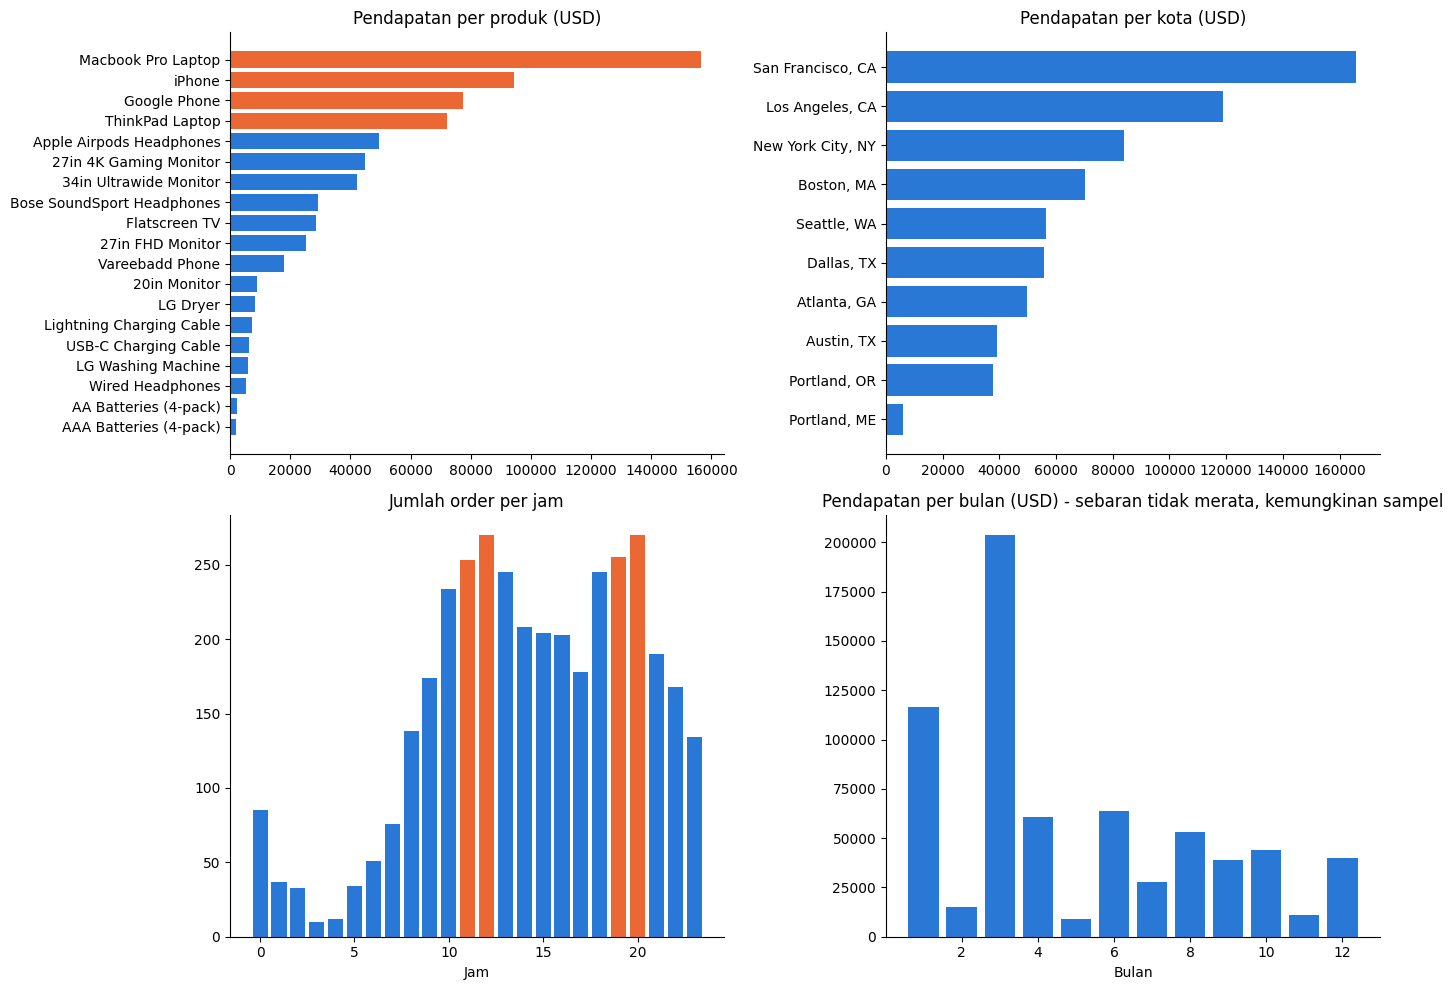

In [ ]:
judul("5. VISUALISASI -> disimpan ke PNG")
BIRU, ORANYE = "#2a78d6", "#eb6834"
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

p = produk["rev"].sort_values()
warna = [ORANYE if x in produk.index[:4] else BIRU for x in p.index]
ax[0, 0].barh(p.index, p.values, color=warna)
ax[0, 0].set_title("Pendapatan per produk (USD)")

k = kota["rev"].sort_values()
ax[0, 1].barh(k.index, k.values, color=BIRU)
ax[0, 1].set_title("Pendapatan per kota (USD)")

ax[1, 0].bar(jam.index, jam.values, color=[ORANYE if h in (11, 12, 19, 20) else BIRU for h in jam.index])
ax[1, 0].set_title("Jumlah order per jam")
ax[1, 0].set_xlabel("Jam")

ax[1, 1].bar(bulan.index, bulan["rev"], color=BIRU)
ax[1, 1].set_title("Pendapatan per bulan (USD) - sebaran tidak merata, kemungkinan sampel")
ax[1, 1].set_xlabel("Bulan")

for a_ in ax.ravel():
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
print("Tersimpan: hasil_analisis.png")